In [1]:
import pandas as pd

training_data = pd.read_csv("/Users/admin/Desktop/mini_projects/digit_recognition/data/train.csv")

In [2]:
training_data.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
training_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Columns: 785 entries, label to pixel783
dtypes: int64(785)
memory usage: 251.5 MB


## Multinomial logistic regression baseline

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

# Keep the 784 pixels flat and scale their values to [0, 1].
X_logreg = training_data.drop(columns=["label"]).to_numpy(dtype="float32") / 255.0
y_logreg = training_data["label"]

X_logreg_train, X_logreg_val, y_logreg_train, y_logreg_val = train_test_split(
    X_logreg, y_logreg, test_size=0.2, random_state=42, stratify=y_logreg
)

# For ten classes, the lbfgs solver fits a multinomial logistic regression.
logreg_model = LogisticRegression(solver="lbfgs", max_iter=1000)
logreg_model.fit(X_logreg_train, y_logreg_train)

logreg_val_predictions = logreg_model.predict(X_logreg_val)
print(f"Validation accuracy: {accuracy_score(y_logreg_val, logreg_val_predictions):.4f}")

Validation accuracy: 0.9126


## MLP 

Train on the same 80% split used by logistic regression. The held-out 20% is used only to measure out-of-sample (OOS) accuracy after each epoch.

In [5]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)

# Reuse the exact stratified split and normalized pixels from logistic regression.
mlp_train_loader = DataLoader(
    TensorDataset(
        torch.from_numpy(X_logreg_train.copy()),
        torch.as_tensor(y_logreg_train.to_numpy(), dtype=torch.long),
    ),
    batch_size=64,
    shuffle=True,
)
mlp_val_loader = DataLoader(
    TensorDataset(
        torch.from_numpy(X_logreg_val.copy()),
        torch.as_tensor(y_logreg_val.to_numpy(), dtype=torch.long),
    ),
    batch_size=256,
)

mlp_model = nn.Sequential(
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 10),
)
mlp_loss_fn = nn.CrossEntropyLoss()
mlp_optimizer = torch.optim.Adam(mlp_model.parameters(), lr=0.002)


def held_out_accuracy(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.inference_mode():
        for features, labels in loader:
            predictions = model(features).argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)
    return correct / total


mlp_oos_accuracy = []
n_epochs = 10
for epoch in range(n_epochs):
    mlp_model.train()
    total_loss = 0.0
    for features, labels in mlp_train_loader:
        mlp_optimizer.zero_grad()
        loss = mlp_loss_fn(mlp_model(features), labels)
        loss.backward()
        mlp_optimizer.step()
        total_loss += loss.item()

    accuracy = held_out_accuracy(mlp_model, mlp_val_loader)
    mlp_oos_accuracy.append(accuracy)
    print(
        f"Epoch {epoch + 1}/{n_epochs}, "
        f"train loss: {total_loss / len(mlp_train_loader):.4f}, "
        f"OOS accuracy: {accuracy:.4f}"
    )

/var/folders/8c/wkcpgrm54ks5hmrtqmc6r7j80000gp/T/ipykernel_49965/2280653734.py:11: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:219.)
  torch.as_tensor(y_logreg_train.to_numpy(), dtype=torch.long),


Epoch 1/10, train loss: 0.3150, OOS accuracy: 0.9500
Epoch 2/10, train loss: 0.1290, OOS accuracy: 0.9618
Epoch 3/10, train loss: 0.0829, OOS accuracy: 0.9680
Epoch 4/10, train loss: 0.0590, OOS accuracy: 0.9676
Epoch 5/10, train loss: 0.0412, OOS accuracy: 0.9708
Epoch 6/10, train loss: 0.0311, OOS accuracy: 0.9717
Epoch 7/10, train loss: 0.0224, OOS accuracy: 0.9713
Epoch 8/10, train loss: 0.0193, OOS accuracy: 0.9745
Epoch 9/10, train loss: 0.0144, OOS accuracy: 0.9671
Epoch 10/10, train loss: 0.0192, OOS accuracy: 0.9744


## Basic CNN

Use the same training and held-out rows as the logistic regression and MLP, reshaped to 28 × 28 images.

In [6]:
import torch.nn.functional as F

cnn_train_loader = DataLoader(
    TensorDataset(
        torch.from_numpy(X_logreg_train.copy()).reshape(-1, 1, 28, 28),
        torch.as_tensor(y_logreg_train.to_numpy(), dtype=torch.long),
    ),
    batch_size=64,
    shuffle=True,
)
cnn_val_loader = DataLoader(
    TensorDataset(
        torch.from_numpy(X_logreg_val.copy()).reshape(-1, 1, 28, 28),
        torch.as_tensor(y_logreg_val.to_numpy(), dtype=torch.long),
    ),
    batch_size=256,
)


class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.fc = nn.Linear(16 * 14 * 14, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        return self.fc(torch.flatten(x, start_dim=1))


torch.manual_seed(42)
cnn_model = CNN()
cnn_loss_fn = nn.CrossEntropyLoss()
cnn_optimizer = torch.optim.Adam(cnn_model.parameters(), lr=0.001)

cnn_oos_accuracy = []
n_epochs = 10
for epoch in range(n_epochs):
    cnn_model.train()
    total_loss = 0.0
    for features, labels in cnn_train_loader:
        cnn_optimizer.zero_grad()
        loss = cnn_loss_fn(cnn_model(features), labels)
        loss.backward()
        cnn_optimizer.step()
        total_loss += loss.item()

    accuracy = held_out_accuracy(cnn_model, cnn_val_loader)
    cnn_oos_accuracy.append(accuracy)
    print(
        f"Epoch {epoch + 1}/{n_epochs}, "
        f"train loss: {total_loss / len(cnn_train_loader):.4f}, "
        f"OOS accuracy: {accuracy:.4f}"
    )

Epoch 1/10, train loss: 0.4407, OOS accuracy: 0.9312
Epoch 2/10, train loss: 0.1844, OOS accuracy: 0.9539
Epoch 3/10, train loss: 0.1290, OOS accuracy: 0.9646
Epoch 4/10, train loss: 0.0984, OOS accuracy: 0.9689
Epoch 5/10, train loss: 0.0795, OOS accuracy: 0.9723
Epoch 6/10, train loss: 0.0658, OOS accuracy: 0.9738
Epoch 7/10, train loss: 0.0578, OOS accuracy: 0.9769
Epoch 8/10, train loss: 0.0499, OOS accuracy: 0.9783
Epoch 9/10, train loss: 0.0448, OOS accuracy: 0.9770
Epoch 10/10, train loss: 0.0406, OOS accuracy: 0.9786


## OOS accuracy by epoch

Each value is accuracy on the same held-out 20% split; the table shows percentages.


,Epoch,MLP OOS accuracy (%),CNN OOS accuracy (%)
0,1,95.00,93.12
1,2,96.18,95.39
2,3,96.80,96.46
3,4,96.76,96.89
4,5,97.08,97.23
5,6,97.17,97.38
6,7,97.13,97.69
7,8,97.45,97.83
8,9,96.71,97.70
9,10,97.44,97.86


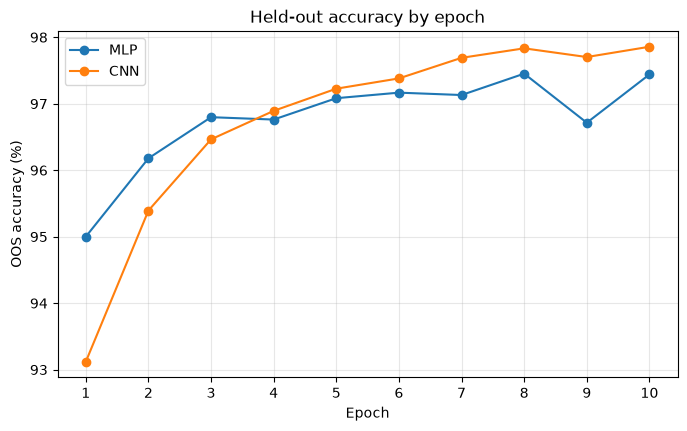

In [8]:
import matplotlib.pyplot as plt
from IPython.display import display

oos_accuracy_table = pd.DataFrame({
    "Epoch": range(1, n_epochs + 1),
    "MLP OOS accuracy (%)": [100 * value for value in mlp_oos_accuracy],
    "CNN OOS accuracy (%)": [100 * value for value in cnn_oos_accuracy],
})
display(oos_accuracy_table.round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(oos_accuracy_table["Epoch"], oos_accuracy_table["MLP OOS accuracy (%)"], marker="o", label="MLP")
ax.plot(oos_accuracy_table["Epoch"], oos_accuracy_table["CNN OOS accuracy (%)"], marker="o", label="CNN")
ax.set(xlabel="Epoch", ylabel="OOS accuracy (%)", title="Held-out accuracy by epoch")
ax.set_xticks(oos_accuracy_table["Epoch"])
ax.grid(alpha=0.3)
ax.legend()
plt.show()